In [1]:
import os, sys, json, time, warnings, textwrap
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Descriptors import MoleculeDescriptors
RDLogger.DisableLog("rdApp.*")

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.linear_model import BayesianRidge, RidgeCV, ElasticNet
from sklearn.svm import SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (GradientBoostingRegressor, RandomForestRegressor,
                              ExtraTreesRegressor, StackingRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, GroupKFold, StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

print("python     :", sys.version.split()[0])
import sklearn, rdkit
print("rdkit      :", rdkit.__version__)
print("scikit-learn:", sklearn.__version__)

python     : 3.11.18
rdkit      : 2026.03.6
scikit-learn: 1.9.1


In [2]:
CSV_LOCAL = "/data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv"

df = pd.read_csv(CSV_LOCAL)
print("Dibaca dari file lokal:", CSV_LOCAL)

df.columns = ["chembl_id", "smiles", "pKd"]
print("Dimensi:", df.shape)
df.head()

Dibaca dari file lokal: /data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv
Dimensi: (53, 3)


,chembl_id,smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
3,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,3.823909


In [3]:
# Validasi struktur & kanonikalisasi SMILES
mols, bad = [], []
for i, s in enumerate(df.smiles):
    m = Chem.MolFromSmiles(s)
    if m is None:
        bad.append(i)
    mols.append(m)

print(f"SMILES valid : {sum(m is not None for m in mols)}/{len(mols)}")
print(f"SMILES gagal : {len(bad)}")

df["canonical_smiles"] = [Chem.MolToSmiles(m) if m else None for m in mols]
dup = df.canonical_smiles.duplicated().sum()
print(f"Duplikat canonical SMILES: {dup}   (harus 0 — konsisten dengan audit KNIME)")

y = df.pKd.values.astype(float)
print(f"\nStatistik target pKd  n={len(y)}")
print(f"  min {y.min():.4f} | Q1 {np.quantile(y,.25):.4f} | median {np.median(y):.4f} "
      f"| Q3 {np.quantile(y,.75):.4f} | max {y.max():.4f}")
print(f"  mean {y.mean():.4f} | sd {y.std(ddof=1):.4f} | rentang {y.max()-y.min():.4f}")
print(f"  jumlah senyawa pKd > 5 : {(y>5).sum()}  ({(y>5).mean()*100:.1f}%)")

SMILES valid : 53/53
SMILES gagal : 0
Duplikat canonical SMILES: 0   (harus 0 — konsisten dengan audit KNIME)

Statistik target pKd  n=53
  min 3.5686 | Q1 4.0605 | median 4.3768 | Q3 4.6778 | max 5.5528
  mean 4.3942 | sd 0.4649 | rentang 1.9842
  jumlah senyawa pKd > 5 : 7  (13.2%)


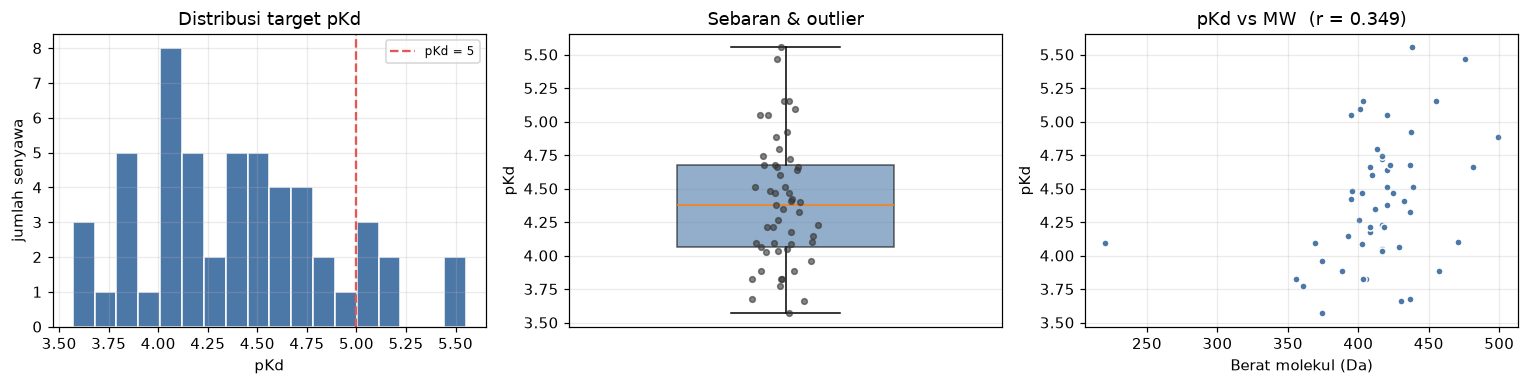

Korelasi Pearson MW–pKd: 0.3495  -> ada tren ukuran molekul


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

ax[0].hist(y, bins=18, color="#4C78A8", edgecolor="white")
ax[0].axvline(5, ls="--", c="#E45756", lw=1.5, label="pKd = 5")
ax[0].set_xlabel("pKd"); ax[0].set_ylabel("jumlah senyawa")
ax[0].set_title("Distribusi target pKd"); ax[0].legend(fontsize=8)

ax[1].boxplot(y, vert=True, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor="#4C78A8", alpha=.6))
ax[1].scatter(np.random.normal(1, .04, len(y)), y, s=14, c="#333", alpha=.6, zorder=3)
ax[1].set_ylabel("pKd"); ax[1].set_title("Sebaran & outlier"); ax[1].set_xticks([])

mw  = np.array([Descriptors.MolWt(m) for m in mols])
ax[2].scatter(mw, y, s=22, c="#4C78A8", edgecolor="white")
ax[2].set_xlabel("Berat molekul (Da)"); ax[2].set_ylabel("pKd")
r_mw = pearsonr(mw, y)[0]
ax[2].set_title(f"pKd vs MW  (r = {r_mw:.3f})")
plt.tight_layout(); plt.show()

print(f"Korelasi Pearson MW–pKd: {r_mw:.4f}  -> "
      f"{'ada tren ukuran molekul' if abs(r_mw)>0.3 else 'ukuran molekul saja tidak cukup'}")

In [6]:
# Scaffold Bemis-Murcko: dasar protokol evaluasi paling ketat
def murcko(smiles_list):
    out = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        sc = MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False)
        out.append(sc if sc else s)
    return np.array(out)

scaf = murcko(df.canonical_smiles)
df["scaffold"] = scaf
vc = pd.Series(scaf).value_counts()

print(f"Jumlah scaffold unik : {len(vc)} dari {len(scaf)} senyawa")
print(f"Scaffold singleton   : {(vc==1).sum()}")
print(f"Scaffold terbesar    : {vc.iloc[0]} senyawa ({vc.iloc[0]/len(scaf)*100:.1f}% dataset)")
print("\n5 scaffold terbanyak:")
for s, c in vc.head(5).items():
    print(f"  n={c:>3}  {s}")

Jumlah scaffold unik : 25 dari 53 senyawa
Scaffold singleton   : 21
Scaffold terbesar    : 23 senyawa (43.4% dataset)

5 scaffold terbanyak:
  n= 23  O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1
  n=  3  O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1
  n=  3  O=S(=O)(c1cccs1)N1CCC(c2ccccc2)CC1
  n=  3  O=S(=O)(c1ccccc1)N1CCC(N2CCCC2)CC1
  n=  1  O=C1Cc2ccccc2N1C1CCN(S(=O)(=O)c2ccccc2)CC1


In [7]:
t0 = time.time()

# --- Blok 1: deskriptor 2D RDKit ---
desc_names = [d[0] for d in Descriptors._descList]
calc = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)
DESC = np.array([calc.CalcDescriptors(m) for m in mols], dtype=float)

# --- Blok 2: Morgan count fingerprint r=2, 1024 bit ---
mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
MORGAN = np.array([mgen.GetCountFingerprintAsNumPy(m) for m in mols], dtype=float)

# --- Blok 3: MACCS keys ---
MACCS = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=float)

# Bersihkan nilai tak hingga pada deskriptor (beberapa deskriptor RDKit bisa NaN/Inf)
n_nan = int(np.isnan(DESC).sum()); n_inf = int(np.isinf(DESC).sum())
DESC = np.nan_to_num(DESC, nan=0.0, posinf=0.0, neginf=0.0)

print(f"DESC   : {DESC.shape}   (NaN diganti: {n_nan}, Inf diganti: {n_inf})")
print(f"MORGAN : {MORGAN.shape}   bit aktif  : {(MORGAN.sum(0)>0).sum()}/1024")
print(f"MACCS  : {MACCS.shape}    key aktif  : {(MACCS.sum(0)>0).sum()}/167")
print(f"\nWaktu featurization: {time.time()-t0:.1f} s")

DESC   : (53, 217)   (NaN diganti: 8, Inf diganti: 0)
MORGAN : (53, 1024)   bit aktif  : 299/1024
MACCS  : (53, 167)    key aktif  : 113/167

Waktu featurization: 0.6 s


In [8]:
# Matriks gabungan + indeks blok (agar setiap model bisa memilih bloknya sendiri)
X = np.hstack([DESC, MORGAN, MACCS])
nD, nM = DESC.shape[1], MORGAN.shape[1]

IDX_DESC   = np.arange(nD)
IDX_MORGAN = np.arange(nD, nD + nM)
IDX_MACCS  = np.arange(nD + nM, X.shape[1])
IDX_FPMA   = np.concatenate([IDX_MORGAN, IDX_MACCS])   # fingerprint + MACCS
IDX_DESCFP = np.concatenate([IDX_DESC,   IDX_MORGAN])  # deskriptor + fingerprint

print(f"X gabungan: {X.shape}")
print(f"  DESC            : kolom {IDX_DESC[0]}..{IDX_DESC[-1]}")
print(f"  MORGAN          : kolom {IDX_MORGAN[0]}..{IDX_MORGAN[-1]}")
print(f"  MACCS           : kolom {IDX_MACCS[0]}..{IDX_MACCS[-1]}")
print(f"  rasio fitur:sampel = {X.shape[1]}:{X.shape[0]} = {X.shape[1]/X.shape[0]:.0f}:1  "
      f"-> regularisasi wajib, bukan opsional")

X gabungan: (53, 1408)
  DESC            : kolom 0..216
  MORGAN          : kolom 217..1240
  MACCS           : kolom 1241..1407
  rasio fitur:sampel = 1408:53 = 27:1  -> regularisasi wajib, bukan opsional


In [9]:
RUN_SCREENING = False   # ubah ke True untuk mereproduksi screening penuh

def make_pre(k=None):
    """Praproses: imputasi -> buang fitur konstan -> (opsional) seleksi k terbaik -> standardisasi."""
    steps = [("imp", SimpleImputer(strategy="median")),
             ("vt",  VarianceThreshold(0.0))]
    if k:
        steps.append(("sel", SelectKBest(f_regression, k=k)))
    steps.append(("sc", StandardScaler()))
    return steps

class BlockSelector(BaseEstimator, TransformerMixin):
    """
    Transformer pemilih kolom blok fitur.

    Ditulis sebagai kelas (bukan FunctionTransformer dengan lambda) agar model
    final dapat di-pickle/di-joblib.dump tanpa error.
    """
    def __init__(self, idx):
        self.idx = idx
    def fit(self, Xm, ym=None):
        return self
    def transform(self, Xm):
        return np.asarray(Xm)[:, self.idx]

def pick(idx):
    return BlockSelector(idx)

def make_pipe(idx, model, k=None):
    return Pipeline([("pick", pick(idx))] + make_pre(k) + [("m", model)])

def cv_random(estimator_factory, Xm, ym, n_repeats=5, n_splits=5, seed0=200):
    """Repeated K-Fold CV. Mengembalikan per-ulangan metrik + rata-rata prediksi OOF."""
    recs, oofs = [], []
    for rep in range(n_repeats):
        cv = KFold(n_splits, shuffle=True, random_state=seed0 + rep)
        p = np.zeros(len(ym))
        for tr, te in cv.split(Xm):
            mdl = estimator_factory()
            mdl.fit(Xm[tr], ym[tr])
            p[te] = np.ravel(mdl.predict(Xm[te]))
        recs.append(dict(rep=rep,
                         RMSE=np.sqrt(mean_squared_error(ym, p)),
                         MAE=mean_absolute_error(ym, p),
                         R2=r2_score(ym, p)))
        oofs.append(p)
    return pd.DataFrame(recs), np.mean(oofs, axis=0)

print("Fungsi evaluasi siap. RUN_SCREENING =", RUN_SCREENING)


Fungsi evaluasi siap. RUN_SCREENING = False


In [12]:
from sklearn.linear_model import BayesianRidge, RidgeCV, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.kernel_ridge import KernelRidge

# Memeriksa XGBoost
try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

# Memeriksa LightGBM
try:
    from lightgbm import LGBMRegressor
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False

print("XGBoost tersedia:", HAS_XGBOOST)
print("LightGBM tersedia:", HAS_LIGHTGBM)

# Daftar algoritma
MODEL_FACTORIES = {
    "BayesianRidge": lambda: BayesianRidge(),

    "PLS_6": lambda: PLSRegression(n_components=6),

    "RidgeCV": lambda: RidgeCV(
        alphas=np.logspace(-3, 3, 30)
    ),

    "ExtraTrees": lambda: ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "GradientBoosting": lambda: GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=3,
        loss="huber",
        random_state=42
    ),

    "RandomForest": lambda: RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "ElasticNet": lambda: ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=10000
    ),

    "GaussianProcess_RBF": lambda: GaussianProcessRegressor(
        kernel=ConstantKernel(1.0) * RBF(length_scale=1.0),
        alpha=0.01,
        normalize_y=True,
        random_state=42
    ),

    "SVR_RBF": lambda: SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ),

    "KNN_5": lambda: KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    ),

    "KernelRidge_RBF": lambda: KernelRidge(
        alpha=1.0,
        kernel="rbf"
    ),

    "SVR_Linear": lambda: SVR(
        kernel="linear",
        C=1.0,
        epsilon=0.1
    )
}

if HAS_XGBOOST:
    MODEL_FACTORIES["XGBoost"] = lambda: XGBRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

if HAS_LIGHTGBM:
    MODEL_FACTORIES["LightGBM"] = lambda: LGBMRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

print("\nJumlah algoritma tersedia:", len(MODEL_FACTORIES))
print("\nDaftar algoritma:")

for i, name in enumerate(MODEL_FACTORIES, 1):
    print(f"{i:2d}. {name}")

XGBoost tersedia: True
LightGBM tersedia: True

Jumlah algoritma tersedia: 14

Daftar algoritma:
 1. BayesianRidge
 2. PLS_6
 3. RidgeCV
 4. ExtraTrees
 5. GradientBoosting
 6. RandomForest
 7. ElasticNet
 8. GaussianProcess_RBF
 9. SVR_RBF
10. KNN_5
11. KernelRidge_RBF
12. SVR_Linear
13. XGBoost
14. LightGBM


In [13]:
# Menghapus SVR Linear dari screening utama
MODEL_FACTORIES.pop("SVR_Linear")

print("Jumlah algoritma screening:", len(MODEL_FACTORIES))
print("\nDaftar algoritma:")

for i, name in enumerate(MODEL_FACTORIES, 1):
    print(f"{i:2d}. {name}")

Jumlah algoritma screening: 13

Daftar algoritma:
 1. BayesianRidge
 2. PLS_6
 3. RidgeCV
 4. ExtraTrees
 5. GradientBoosting
 6. RandomForest
 7. ElasticNet
 8. GaussianProcess_RBF
 9. SVR_RBF
10. KNN_5
11. KernelRidge_RBF
12. XGBoost
13. LightGBM


In [15]:
FEATURE_BLOCKS = {
    "DESC": IDX_DESC,
    "MORGAN": IDX_MORGAN,
    "MACCS": IDX_MACCS,
    "MORGAN+MACCS": np.concatenate([IDX_MORGAN, IDX_MACCS]),
    "DESC+MORGAN": np.concatenate([IDX_DESC, IDX_MORGAN]),
    "DESC+MACCS": np.concatenate([IDX_DESC, IDX_MACCS]),
    "DESC+MORGAN+MACCS": np.arange(X.shape[1])
}

print("Jumlah kombinasi:", len(FEATURE_BLOCKS))

for name, idx in FEATURE_BLOCKS.items():
    print(f"{name:22s}: {len(idx)} fitur")

Jumlah kombinasi: 7
DESC                  : 217 fitur
MORGAN                : 1024 fitur
MACCS                 : 167 fitur
MORGAN+MACCS          : 1191 fitur
DESC+MORGAN           : 1241 fitur
DESC+MACCS            : 384 fitur
DESC+MORGAN+MACCS     : 1408 fitur


In [16]:
SELECT_K_VALUES = [10, 20, 30, None]

print("Konfigurasi SelectKBest:")

for k in SELECT_K_VALUES:
    label = "Semua fitur" if k is None else f"{k} fitur"
    print("-", label)

print("\nJumlah tingkat seleksi:", len(SELECT_K_VALUES))

# Total konfigurasi
total_config = (
    len(MODEL_FACTORIES)
    * len(FEATURE_BLOCKS)
    * len(SELECT_K_VALUES)
)

print("Total konfigurasi screening:", total_config)
print("Total proses fitting:", total_config * 4 * 5)

Konfigurasi SelectKBest:
- 10 fitur
- 20 fitur
- 30 fitur
- Semua fitur

Jumlah tingkat seleksi: 4
Total konfigurasi screening: 364
Total proses fitting: 7280


In [17]:
import os
import time
import warnings

OUTPUT_DIR = "/data/Zira/Model/Model_1_re_run"
SCREENING_DIR = os.path.join(OUTPUT_DIR, "Screening_53")

os.makedirs(SCREENING_DIR, exist_ok=True)

print("Direktori screening:", SCREENING_DIR)
print("Direktori tersedia:", os.path.exists(SCREENING_DIR))

Direktori screening: /data/Zira/Model/Model_1_re_run/Screening_53
Direktori tersedia: True


In [18]:
import traceback
from sklearn.base import clone

RUN_SCREENING = True

N_REPEATS = 4
N_SPLITS = 5
SEED0 = 200

screening_results = []
failed_results = []

result_file = os.path.join(
    SCREENING_DIR, "Screening_All_Results.csv"
)

error_file = os.path.join(
    SCREENING_DIR, "Screening_Failed_Configurations.csv"
)

configurations = []

for model_name, factory in MODEL_FACTORIES.items():
    for block_name, idx in FEATURE_BLOCKS.items():
        for k in SELECT_K_VALUES:
            configurations.append(
                (model_name, block_name, idx, k, factory)
            )

print("Total konfigurasi:", len(configurations))
print("Screening dimulai...\n")

start_time = time.time()

if RUN_SCREENING:

    for number, (model_name, block_name, idx, k, factory) in enumerate(
        configurations, start=1
    ):

        config_name = (
            f"{model_name}_{block_name}_"
            f"{'ALL' if k is None else k}"
        )

        print(
            f"[{number}/{len(configurations)}] {config_name}",
            flush=True
        )

        try:
            fold_records = []

            for rep in range(N_REPEATS):

                cv = KFold(
                    n_splits=N_SPLITS,
                    shuffle=True,
                    random_state=SEED0 + rep
                )

                predictions = np.zeros(len(y))

                for train_idx, test_idx in cv.split(X):

                    X_train = X[train_idx][:, idx]
                    X_test = X[test_idx][:, idx]

                    y_train = y[train_idx]
                    y_test = y[test_idx]

                    # Preprocessing hanya fit pada data training
                    imputer = SimpleImputer(strategy="median")
                    X_train = imputer.fit_transform(X_train)
                    X_test = imputer.transform(X_test)

                    variance = VarianceThreshold(0.0)
                    X_train = variance.fit_transform(X_train)
                    X_test = variance.transform(X_test)

                    if X_train.shape[1] == 0:
                        raise ValueError("Tidak ada fitur setelah VarianceThreshold.")

                    # Seleksi fitur
                    if k is not None:
                        k_actual = min(k, X_train.shape[1])

                        selector = SelectKBest(
                            score_func=f_regression,
                            k=k_actual
                        )

                        X_train = selector.fit_transform(X_train, y_train)
                        X_test = selector.transform(X_test)

                    # Standardisasi
                    scaler = StandardScaler()
                    X_train = scaler.fit_transform(X_train)
                    X_test = scaler.transform(X_test)

                    # Membuat model
                    model = factory()

                    # Menyesuaikan komponen PLS bila diperlukan
                    if model_name == "PLS_6":
                        model.n_components = min(
                            6,
                            X_train.shape[1],
                            X_train.shape[0] - 1
                        )

                    model.fit(X_train, y_train)

                    predictions[test_idx] = np.ravel(
                        model.predict(X_test)
                    )

                fold_records.append({
                    "Repeat": rep + 1,
                    "RMSE": np.sqrt(mean_squared_error(y, predictions)),
                    "MAE": mean_absolute_error(y, predictions),
                    "R2": r2_score(y, predictions)
                })

            fold_df = pd.DataFrame(fold_records)

            screening_results.append({
                "Model": model_name,
                "Feature_Block": block_name,
                "SelectKBest": "ALL" if k is None else k,
                "RMSE_Mean": fold_df["RMSE"].mean(),
                "RMSE_SD": fold_df["RMSE"].std(),
                "MAE_Mean": fold_df["MAE"].mean(),
                "MAE_SD": fold_df["MAE"].std(),
                "R2_Mean": fold_df["R2"].mean(),
                "R2_SD": fold_df["R2"].std()
            })

        except Exception as e:

            failed_results.append({
                "Model": model_name,
                "Feature_Block": block_name,
                "SelectKBest": "ALL" if k is None else k,
                "Error": str(e)
            })

        # Simpan progres setelah setiap konfigurasi
        pd.DataFrame(screening_results).to_csv(
            result_file, index=False
        )

        pd.DataFrame(failed_results).to_csv(
            error_file, index=False
        )

    elapsed = time.time() - start_time

    print("\nSCREENING SELESAI")
    print(f"Waktu: {elapsed/60:.2f} menit")
    print("Berhasil:", len(screening_results))
    print("Gagal:", len(failed_results))
    print("Hasil:", result_file)

Total konfigurasi: 364
Screening dimulai...

[1/364] BayesianRidge_DESC_10
[2/364] BayesianRidge_DESC_20
[3/364] BayesianRidge_DESC_30
[4/364] BayesianRidge_DESC_ALL
[5/364] BayesianRidge_MORGAN_10
[6/364] BayesianRidge_MORGAN_20
[7/364] BayesianRidge_MORGAN_30
[8/364] BayesianRidge_MORGAN_ALL
[9/364] BayesianRidge_MACCS_10
[10/364] BayesianRidge_MACCS_20
[11/364] BayesianRidge_MACCS_30
[12/364] BayesianRidge_MACCS_ALL
[13/364] BayesianRidge_MORGAN+MACCS_10
[14/364] BayesianRidge_MORGAN+MACCS_20
[15/364] BayesianRidge_MORGAN+MACCS_30
[16/364] BayesianRidge_MORGAN+MACCS_ALL
[17/364] BayesianRidge_DESC+MORGAN_10
[18/364] BayesianRidge_DESC+MORGAN_20
[19/364] BayesianRidge_DESC+MORGAN_30
[20/364] BayesianRidge_DESC+MORGAN_ALL
[21/364] BayesianRidge_DESC+MACCS_10
[22/364] BayesianRidge_DESC+MACCS_20
[23/364] BayesianRidge_DESC+MACCS_30
[24/364] BayesianRidge_DESC+MACCS_ALL
[25/364] BayesianRidge_DESC+MORGAN+MACCS_10
[26/364] BayesianRidge_DESC+MORGAN+MACCS_20
[27/364] BayesianRidge_DESC+MO

In [19]:
import os
import pandas as pd

SCREENING_DIR = "/data/Zira/Model/Model_1_re_run/Screening_53"

# Memuat hasil screening
results = pd.read_csv(
    os.path.join(SCREENING_DIR, "Screening_All_Results.csv")
)

failed = pd.read_csv(
    os.path.join(SCREENING_DIR, "Screening_Failed_Configurations.csv")
)

print("JUMLAH HASIL BERHASIL:", len(results))
print("JUMLAH KONFIGURASI GAGAL:", len(failed))

print("\n=== KONFIGURASI YANG GAGAL ===")
display(failed)

print("\n=== 15 KONFIGURASI TERBAIK BERDASARKAN RMSE ===")

top_results = results.sort_values(
    "RMSE_Mean",
    ascending=True
).head(15)

display(top_results.round(4))

print("\n=== RINGKASAN PERFORMA SETIAP ALGORITMA ===")

model_summary = (
    results.sort_values("RMSE_Mean")
    .groupby("Model", as_index=False)
    .first()
    .sort_values("RMSE_Mean")
)

display(model_summary.round(4))

JUMLAH HASIL BERHASIL: 362
JUMLAH KONFIGURASI GAGAL: 2

=== KONFIGURASI YANG GAGAL ===


,Model,Feature_Block,SelectKBest,Error
0,PLS_6,DESC+MORGAN,10,A has a NaN entry
1,PLS_6,DESC+MORGAN+MACCS,10,A has a NaN entry



=== 15 KONFIGURASI TERBAIK BERDASARKAN RMSE ===


,Model,Feature_Block,SelectKBest,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
43,PLS_6,MORGAN+MACCS,ALL,0.2842,0.0181,0.2146,0.0149,0.6181,0.0490
15,BayesianRidge,MORGAN+MACCS,ALL,0.2849,0.0166,0.2164,0.0124,0.6162,0.0455
69,RidgeCV,MORGAN+MACCS,ALL,0.2856,0.0167,0.2125,0.0144,0.6144,0.0459
7,BayesianRidge,MORGAN,ALL,0.2875,0.0197,0.2149,0.0169,0.6089,0.0546
61,RidgeCV,MORGAN,ALL,0.2883,0.0196,0.2153,0.0171,0.6066,0.0545
35,PLS_6,MORGAN,ALL,0.2893,0.0200,0.2180,0.0163,0.6041,0.0552
181,ElasticNet,MORGAN+MACCS,ALL,0.2966,0.0167,0.2211,0.0172,0.5842,0.0479
173,ElasticNet,MORGAN,ALL,0.3058,0.0165,0.2326,0.0152,0.5581,0.0487
171,ElasticNet,MORGAN,20,0.3085,0.0178,0.2398,0.0204,0.5503,0.0518
5,BayesianRidge,MORGAN,20,0.3089,0.0125,0.2414,0.0141,0.5495,0.0361



=== RINGKASAN PERFORMA SETIAP ALGORITMA ===


,Model,Feature_Block,SelectKBest,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
8,PLS_6,MORGAN+MACCS,ALL,0.2842,0.0181,0.2146,0.0149,0.6181,0.0490
0,BayesianRidge,MORGAN+MACCS,ALL,0.2849,0.0166,0.2164,0.0124,0.6162,0.0455
10,RidgeCV,MORGAN+MACCS,ALL,0.2856,0.0167,0.2125,0.0144,0.6144,0.0459
1,ElasticNet,MORGAN+MACCS,ALL,0.2966,0.0167,0.2211,0.0172,0.5842,0.0479
11,SVR_RBF,MORGAN,ALL,0.3225,0.0127,0.2536,0.0098,0.5090,0.0389
12,XGBoost,MORGAN,ALL,0.3352,0.0238,0.2591,0.0182,0.4682,0.0776
4,GradientBoosting,DESC+MORGAN+MACCS,30,0.3357,0.0151,0.2654,0.0107,0.4677,0.0479
2,ExtraTrees,DESC,ALL,0.3378,0.0129,0.2713,0.0097,0.4614,0.0412
5,KNN_5,DESC+MORGAN,30,0.3406,0.0113,0.2708,0.0030,0.4526,0.0360
9,RandomForest,MORGAN,30,0.3406,0.0282,0.2604,0.0223,0.4502,0.0914


In [20]:
print("=== PEMERIKSAAN DATASET AWAL ===")

print("Shape X:", X.shape)
print("Jumlah NaN:", np.isnan(X).sum())
print("Jumlah Inf:", np.isinf(X).sum())

print("\n=== PEMERIKSAAN SETIAP BLOK FITUR ===")

for name, idx in FEATURE_BLOCKS.items():
    X_block = X[:, idx]

    print(
        name,
        "| Shape:", X_block.shape,
        "| NaN:", np.isnan(X_block).sum(),
        "| Inf:", np.isinf(X_block).sum()
    )

=== PEMERIKSAAN DATASET AWAL ===
Shape X: (53, 1408)
Jumlah NaN: 0
Jumlah Inf: 0

=== PEMERIKSAAN SETIAP BLOK FITUR ===
DESC | Shape: (53, 217) | NaN: 0 | Inf: 0
MORGAN | Shape: (53, 1024) | NaN: 0 | Inf: 0
MACCS | Shape: (53, 167) | NaN: 0 | Inf: 0
MORGAN+MACCS | Shape: (53, 1191) | NaN: 0 | Inf: 0
DESC+MORGAN | Shape: (53, 1241) | NaN: 0 | Inf: 0
DESC+MACCS | Shape: (53, 384) | NaN: 0 | Inf: 0
DESC+MORGAN+MACCS | Shape: (53, 1408) | NaN: 0 | Inf: 0


In [21]:
import numpy as np

print("=== PEMERIKSAAN TARGET pKd ===")
print("Jumlah data:", len(y))
print("Jumlah NaN:", np.isnan(y).sum())
print("Jumlah Inf:", np.isinf(y).sum())
print("Nilai minimum:", np.nanmin(y))
print("Nilai maksimum:", np.nanmax(y))
print("Standar deviasi:", np.nanstd(y))

print("\n=== PEMERIKSAAN NILAI TARGET ===")
print(y)

=== PEMERIKSAAN TARGET pKd ===
Jumlah data: 53
Jumlah NaN: 0
Jumlah Inf: 0
Nilai minimum: 3.568636235841014
Nilai maksimum: 5.552841968657781
Standar deviasi: 0.46053555484687536

=== PEMERIKSAAN NILAI TARGET ===
[3.88605665 4.34678749 4.63827216 4.10237291 3.82390874 5.55284197
 4.14874165 4.32790214 4.65757732 5.09691001 4.26760624 5.46852108
 4.7212464  3.67778071 4.09691001 4.37675071 5.04575749 4.1739252
 4.48148606 4.06048075 3.95860731 3.82390874 4.04575749 3.88605665
 4.88605665 4.92081875 4.02687215 4.4202164  4.46852108 4.60205999
 4.67778071 4.22914799 4.50863831 4.21467016 4.39794001 4.67778071
 4.46852108 3.82390874 4.74472749 5.15490196 4.65757732 3.56863624
 5.15490196 3.76955108 5.04575749 4.21467016 4.03621217 3.65757732
 4.40893539 4.50863831 4.08618615 4.79588002 4.09691001]


In [22]:
import os
import pandas as pd

SCREENING_DIR = "/data/Zira/Model/Model_1_re_run/Screening_53"

results = pd.read_csv(
    os.path.join(SCREENING_DIR, "Screening_All_Results.csv")
)

candidate_models = ["PLS_6", "BayesianRidge", "RidgeCV"]

candidate_summary = (
    results[results["Model"].isin(candidate_models)]
    .sort_values("RMSE_Mean")
    .groupby("Model", as_index=False)
    .first()
)

candidate_summary = candidate_summary[
    [
        "Model",
        "Feature_Block",
        "SelectKBest",
        "RMSE_Mean",
        "RMSE_SD",
        "MAE_Mean",
        "MAE_SD",
        "R2_Mean",
        "R2_SD"
    ]
].sort_values("RMSE_Mean")

print("=== PERBANDINGAN TIGA KANDIDAT TERBAIK ===")
display(candidate_summary.round(4))

output_file = os.path.join(
    SCREENING_DIR,
    "Screening_Top3_Candidates.csv"
)

candidate_summary.to_csv(output_file, index=False)

print("Tabel tersimpan di:", output_file)

=== PERBANDINGAN TIGA KANDIDAT TERBAIK ===


,Model,Feature_Block,SelectKBest,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
1,PLS_6,MORGAN+MACCS,ALL,0.2842,0.0181,0.2146,0.0149,0.6181,0.0490
0,BayesianRidge,MORGAN+MACCS,ALL,0.2849,0.0166,0.2164,0.0124,0.6162,0.0455
2,RidgeCV,MORGAN+MACCS,ALL,0.2856,0.0167,0.2125,0.0144,0.6144,0.0459


Tabel tersimpan di: /data/Zira/Model/Model_1_re_run/Screening_53/Screening_Top3_Candidates.csv


In [35]:

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import BayesianRidge, RidgeCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
import numpy as np

# Nama anggota ensemble
MEMBER_NAMES = [
    "M1_PLS6_MORGAN+MACCS",
    "M2_BayesianRidge_MORGAN+MACCS",
    "M3_RidgeCV_MORGAN+MACCS"
]

# Ensemble rata-rata berbobot
class AverageBlend(BaseEstimator, RegressorMixin):

    def __init__(self, members=None, weights=None):
        self.members = members
        self.weights = weights

    def fit(self, Xm, ym):

        self.fitted_ = [
            clone(m).fit(Xm, ym)
            for m in self.members
        ]

        w = (
            np.ones(len(self.fitted_))
            if self.weights is None
            else np.asarray(self.weights, dtype=float)
        )

        self.w_ = w / w.sum()

        return self

    def predict(self, Xm):

        preds = np.vstack([
            np.ravel(m.predict(Xm))
            for m in self.fitted_
        ])

        return np.dot(self.w_, preds)

    def predict_members(self, Xm):

        return np.vstack([
            np.ravel(m.predict(Xm))
            for m in self.fitted_
        ])


# Pabrik pipeline anggota ensemble
def make_member(i):

    preprocessing = [
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler())
    ]

    if i == 0:
        model = PLSRegression(n_components=6)

    elif i == 1:
        model = BayesianRidge()

    elif i == 2:
        model = RidgeCV(
            alphas=np.logspace(-3, 3, 30)
        )

    else:
        raise ValueError(i)

    return Pipeline(
        preprocessing + [("model", model)]
    )


# Model final
def make_model():

    return AverageBlend(
        members=[
            make_member(i) for i in range(3)
        ],
        weights=[1/3, 1/3, 1/3]
    )


print("Model final:")
for i, name in enumerate(MEMBER_NAMES):
    print(f"  {name}")

print("\nPenggabungan: rata-rata bobot sama (1/3 tiap anggota)")


Model final:
  M1_PLS6_MORGAN+MACCS
  M2_BayesianRidge_MORGAN+MACCS
  M3_RidgeCV_MORGAN+MACCS

Penggabungan: rata-rata bobot sama (1/3 tiap anggota)


In [38]:
res_A, oof_A = cv_random(make_model, X, y, n_repeats=5, n_splits=5, seed0=200)

print("=== PROTOKOL A: 5-fold CV, 5 ulangan ===\n")
display(res_A.round(4))

summ_A = dict(
    RMSE=res_A.RMSE.mean(), RMSE_sd=res_A.RMSE.std(ddof=1),
    MAE=res_A.MAE.mean(),   MAE_sd=res_A.MAE.std(ddof=1),
    R2=res_A.R2.mean(),     R2_sd=res_A.R2.std(ddof=1))

print(f"\nRMSE = {summ_A['RMSE']:.4f} ± {summ_A['RMSE_sd']:.4f}")
print(f"MAE  = {summ_A['MAE']:.4f} ± {summ_A['MAE_sd']:.4f}")
print(f"R²   = {summ_A['R2']:.4f} ± {summ_A['R2_sd']:.4f}")
print(f"\nPearson r (OOF rata-rata)  = {pearsonr(y, oof_A)[0]:.4f}")
print(f"Spearman ρ (OOF rata-rata) = {spearmanr(y, oof_A)[0]:.4f}")

print(f"{'Model ini':<32} RMSE {summ_A['RMSE']:.4f} | MAE {summ_A['MAE']:.4f} | R² {summ_A['R2']:.4f}")

=== PROTOKOL A: 5-fold CV, 5 ulangan ===



,rep,RMSE,MAE,R2
0,0,0.2744,0.2051,0.6450
1,1,0.2684,0.1987,0.6604
2,2,0.4026,0.2566,0.2358
3,3,0.3752,0.2280,0.3363
4,4,0.3418,0.2523,0.4490



RMSE = 0.3325 ± 0.0598
MAE  = 0.2281 ± 0.0264
R²   = 0.4653 ± 0.1870

Pearson r (OOF rata-rata)  = 0.8059
Spearman ρ (OOF rata-rata) = 0.8070
Model ini                        RMSE 0.3325 | MAE 0.2281 | R² 0.4653


In [39]:
# Perbandingan anggota tunggal vs ensemble, pada CV yang identik
rows = []
member_oofs = {}
for i, nm in enumerate(MEMBER_NAMES):
    r, o = cv_random(lambda i=i: make_member(i), X, y, n_repeats=5, n_splits=5, seed0=200)
    member_oofs[nm] = o
    rows.append(dict(Model=nm, RMSE=r.RMSE.mean(), RMSE_sd=r.RMSE.std(ddof=1),
                     MAE=r.MAE.mean(), R2=r.R2.mean(), R2_sd=r.R2.std(ddof=1)))

rows.append(dict(Model="ENSEMBLE (rata-rata 3)", RMSE=summ_A["RMSE"], RMSE_sd=summ_A["RMSE_sd"],
                 MAE=summ_A["MAE"], R2=summ_A["R2"], R2_sd=summ_A["R2_sd"]))

# Baseline: prediksi = rata-rata target training
rb = []
for rep in range(5):
    cv = KFold(5, shuffle=True, random_state=200 + rep); p = np.zeros(len(y))
    for tr, te in cv.split(X):
        p[te] = y[tr].mean()
    rb.append(dict(RMSE=np.sqrt(mean_squared_error(y, p)), MAE=mean_absolute_error(y, p), R2=r2_score(y, p)))
rb = pd.DataFrame(rb)
rows.append(dict(Model="BASELINE (rata-rata training)", RMSE=rb.RMSE.mean(), RMSE_sd=rb.RMSE.std(ddof=1),
                 MAE=rb.MAE.mean(), R2=rb.R2.mean(), R2_sd=rb.R2.std(ddof=1)))

tab_members = pd.DataFrame(rows)
print("=== Anggota tunggal vs ensemble (protokol CV identik) ===\n")
display(tab_members.round(4))

best_single = tab_members.iloc[:3].R2.max()
print(f"\nAnggota tunggal terbaik : R² {best_single:.4f}")
print(f"Ensemble                : R² {summ_A['R2']:.4f}   (gain {summ_A['R2']-best_single:+.4f})")

=== Anggota tunggal vs ensemble (protokol CV identik) ===



,Model,RMSE,RMSE_sd,MAE,R2,R2_sd
0,M1_PLS6_MORGAN+MACCS,0.3377,0.0605,0.2315,0.4484,0.1927
1,M2_BayesianRidge_MORGAN+MACCS,0.3360,0.0615,0.2370,0.4536,0.1949
2,M3_RidgeCV_MORGAN+MACCS,0.3340,0.0576,0.2305,0.4614,0.1805
3,ENSEMBLE (rata-rata 3),0.3325,0.0598,0.2281,0.4653,0.1870
4,BASELINE (rata-rata training),0.4663,0.0037,0.3789,-0.0251,0.0162



Anggota tunggal terbaik : R² 0.4614
Ensemble                : R² 0.4653   (gain +0.0039)


In [40]:
gkf = GroupKFold(n_splits=5)
oof_B = np.zeros(len(y))
fold_rows = []

for k, (tr, te) in enumerate(gkf.split(X, y, groups=scaf)):
    mdl = make_model().fit(X[tr], y[tr])
    p = mdl.predict(X[te])
    oof_B[te] = p
    fold_rows.append(dict(fold=k + 1, n_train=len(tr), n_test=len(te),
                          n_scaffold_test=len(set(scaf[te])),
                          overlap=len(set(scaf[tr]) & set(scaf[te])),
                          RMSE=np.sqrt(mean_squared_error(y[te], p)),
                          MAE=mean_absolute_error(y[te], p)))

fold_df = pd.DataFrame(fold_rows)
print("=== PROTOKOL B: 5-fold scaffold CV (GroupKFold) ===\n")
display(fold_df.round(4))
print(f"Overlap scaffold train-test total: {fold_df.overlap.sum()}  (harus 0)")

summ_B = dict(RMSE=np.sqrt(mean_squared_error(y, oof_B)),
              MAE=mean_absolute_error(y, oof_B),
              R2=r2_score(y, oof_B))
print(f"\nOOF RMSE = {summ_B['RMSE']:.4f}")
print(f"OOF MAE  = {summ_B['MAE']:.4f}")
print(f"OOF R²   = {summ_B['R2']:.4f}")
print(f"Pearson  = {pearsonr(y, oof_B)[0]:.4f} | Spearman = {spearmanr(y, oof_B)[0]:.4f}")

print(f"{'Model ini':<32} RMSE {summ_B['RMSE']:.4f} | MAE {summ_B['MAE']:.4f} | R² {summ_B['R2']:.4f}")

=== PROTOKOL B: 5-fold scaffold CV (GroupKFold) ===



,fold,n_train,n_test,n_scaffold_test,overlap,RMSE,MAE
0,1,30,23,1,0,0.3021,0.2227
1,2,45,8,6,0,0.2498,0.2000
2,3,45,8,6,0,0.7492,0.5656
3,4,46,7,5,0,0.2520,0.1753
4,5,46,7,7,0,0.3077,0.2860


Overlap scaffold train-test total: 0  (harus 0)

OOF RMSE = 0.3932
OOF MAE  = 0.2732
OOF R²   = 0.2709
Pearson  = 0.5400 | Spearman = 0.5418
Model ini                        RMSE 0.3932 | MAE 0.2732 | R² 0.2709


Matriks korelasi error OOF antar anggota:



,M1,M2,M3
M1,1.000,0.971,0.990
M2,0.971,1.000,0.978
M3,0.990,0.978,1.000


MSE rata-rata anggota : 0.07996
MSE ensemble          : 0.07879
Pengurangan (diversity gain): 0.00117 (1.5%)

Korelasi error M1-M3 = 0.990  <- pasangan paling beragam (linear vs pohon)
Korelasi error M1-M2 = 0.971  <- tinggi (keduanya linear), tapi loss berbeda


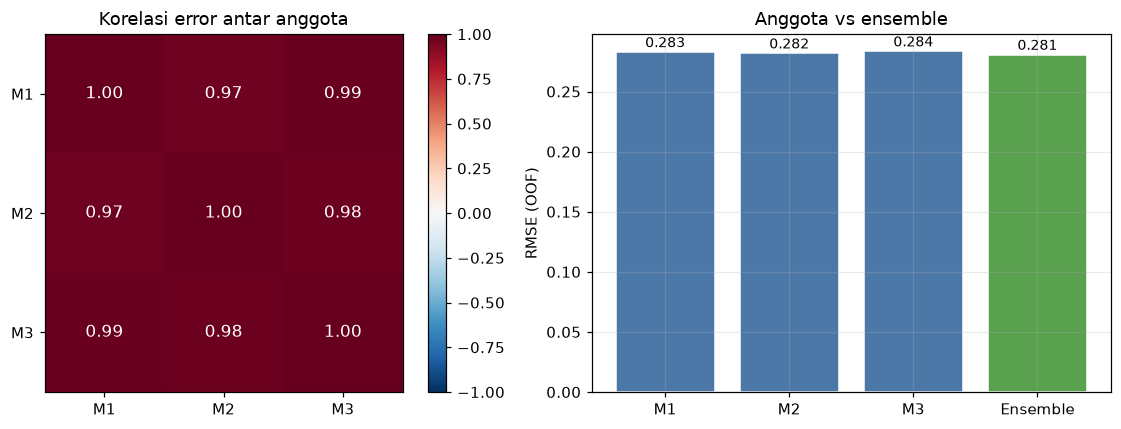

In [41]:
E = np.vstack([member_oofs[n] - y for n in MEMBER_NAMES])       # matriks error OOF
C = np.corrcoef(E)

print("Matriks korelasi error OOF antar anggota:\n")
cm = pd.DataFrame(C, index=["M1", "M2", "M3"], columns=["M1", "M2", "M3"])
display(cm.round(3))

mse_members = (E ** 2).mean(axis=1)
mse_ens     = ((E.mean(axis=0)) ** 2).mean()
print(f"MSE rata-rata anggota : {mse_members.mean():.5f}")
print(f"MSE ensemble          : {mse_ens:.5f}")
print(f"Pengurangan (diversity gain): {mse_members.mean()-mse_ens:.5f} "
      f"({(1-mse_ens/mse_members.mean())*100:.1f}%)")
print(f"\nKorelasi error M1-M3 = {C[0,2]:.3f}  <- pasangan paling beragam (linear vs pohon)")
print(f"Korelasi error M1-M2 = {C[0,1]:.3f}  <- tinggi (keduanya linear), tapi loss berbeda")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(3), ["M1", "M2", "M3"]); ax[0].set_yticks(range(3), ["M1", "M2", "M3"])
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, f"{C[i,j]:.2f}", ha="center", va="center",
                   color="white" if abs(C[i, j]) > .6 else "black", fontsize=11)
ax[0].set_title("Korelasi error antar anggota"); ax[0].grid(False)
plt.colorbar(im, ax=ax[0], fraction=.046)

ax[1].bar(["M1", "M2", "M3", "Ensemble"], list(np.sqrt(mse_members)) + [np.sqrt(mse_ens)],
          color=["#4C78A8", "#4C78A8", "#4C78A8", "#59A14F"], edgecolor="white")
ax[1].set_ylabel("RMSE (OOF)"); ax[1].set_title("Anggota vs ensemble")
for i, v in enumerate(list(np.sqrt(mse_members)) + [np.sqrt(mse_ens)]):
    ax[1].text(i, v + .004, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

=== PROTOKOL C: hold-out 80/20, 20 ulangan (stratified) ===



,split,RMSE,MAE,R2,n_test_pKd5
0,1,0.3464,0.2199,0.4517,2
1,2,0.2592,0.2229,0.7682,3
2,3,0.2575,0.1949,0.4932,1
3,4,0.3370,0.2272,0.3769,1
4,5,0.2746,0.2202,0.6625,1
5,6,0.6298,0.3336,-0.2309,4
6,7,0.3510,0.2550,0.4479,2
7,8,0.2014,0.1714,0.7058,1
8,9,0.2234,0.1743,0.7332,3
9,10,0.4240,0.3210,0.2681,1



RMSE = 0.3084 ± 0.1030   [min 0.1928, max 0.6298]
MAE  = 0.2289
R²   = 0.5054 ± 0.2659   [min -0.2309, max 0.7682]
Model ini (rata-rata 20 split)     RMSE 0.3084 | MAE 0.2289 | R² 0.5054


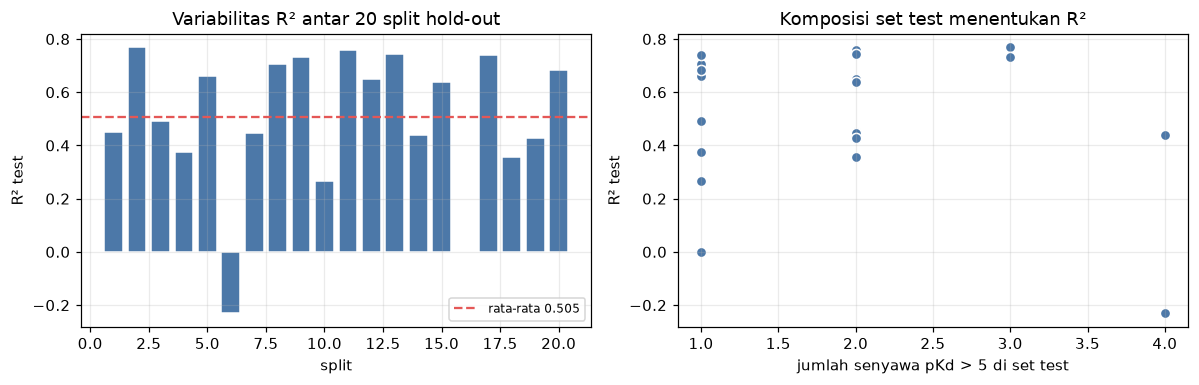

In [42]:
bins = np.digitize(y, np.quantile(y, [.25, .5, .75]))
sss  = StratifiedShuffleSplit(n_splits=20, test_size=16, random_state=SEED)

rows_C = []
for i, (tr, te) in enumerate(sss.split(X, bins)):
    mdl = make_model().fit(X[tr], y[tr])
    p = mdl.predict(X[te])
    rows_C.append(dict(split=i + 1,
                       RMSE=np.sqrt(mean_squared_error(y[te], p)),
                       MAE=mean_absolute_error(y[te], p),
                       R2=r2_score(y[te], p),
                       n_test_pKd5=int((y[te] > 5).sum())))
res_C = pd.DataFrame(rows_C)

print("=== PROTOKOL C: hold-out 80/20, 20 ulangan (stratified) ===\n")
display(res_C.round(4))

summ_C = dict(RMSE=res_C.RMSE.mean(), RMSE_sd=res_C.RMSE.std(ddof=1),
              MAE=res_C.MAE.mean(),  R2=res_C.R2.mean(), R2_sd=res_C.R2.std(ddof=1))
print(f"\nRMSE = {summ_C['RMSE']:.4f} ± {summ_C['RMSE_sd']:.4f}   "
      f"[min {res_C.RMSE.min():.4f}, max {res_C.RMSE.max():.4f}]")
print(f"MAE  = {summ_C['MAE']:.4f}")
print(f"R²   = {summ_C['R2']:.4f} ± {summ_C['R2_sd']:.4f}   "
      f"[min {res_C.R2.min():.4f}, max {res_C.R2.max():.4f}]")

print(f"{'Model ini (rata-rata 20 split)':<34} RMSE {summ_C['RMSE']:.4f} | "
      f"MAE {summ_C['MAE']:.4f} | R² {summ_C['R2']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(res_C.split, res_C.R2, color="#4C78A8", edgecolor="white")
ax[0].axhline(summ_C["R2"], c="#E45756", ls="--", label=f"rata-rata {summ_C['R2']:.3f}")
ax[0].set_xlabel("split"); ax[0].set_ylabel("R² test"); ax[0].legend(fontsize=8)
ax[0].set_title("Variabilitas R² antar 20 split hold-out")
ax[1].scatter(res_C.n_test_pKd5, res_C.R2, s=45, c="#4C78A8", edgecolor="white")
ax[1].set_xlabel("jumlah senyawa pKd > 5 di set test"); ax[1].set_ylabel("R² test")
ax[1].set_title("Komposisi set test menentukan R²")
plt.tight_layout(); plt.show()

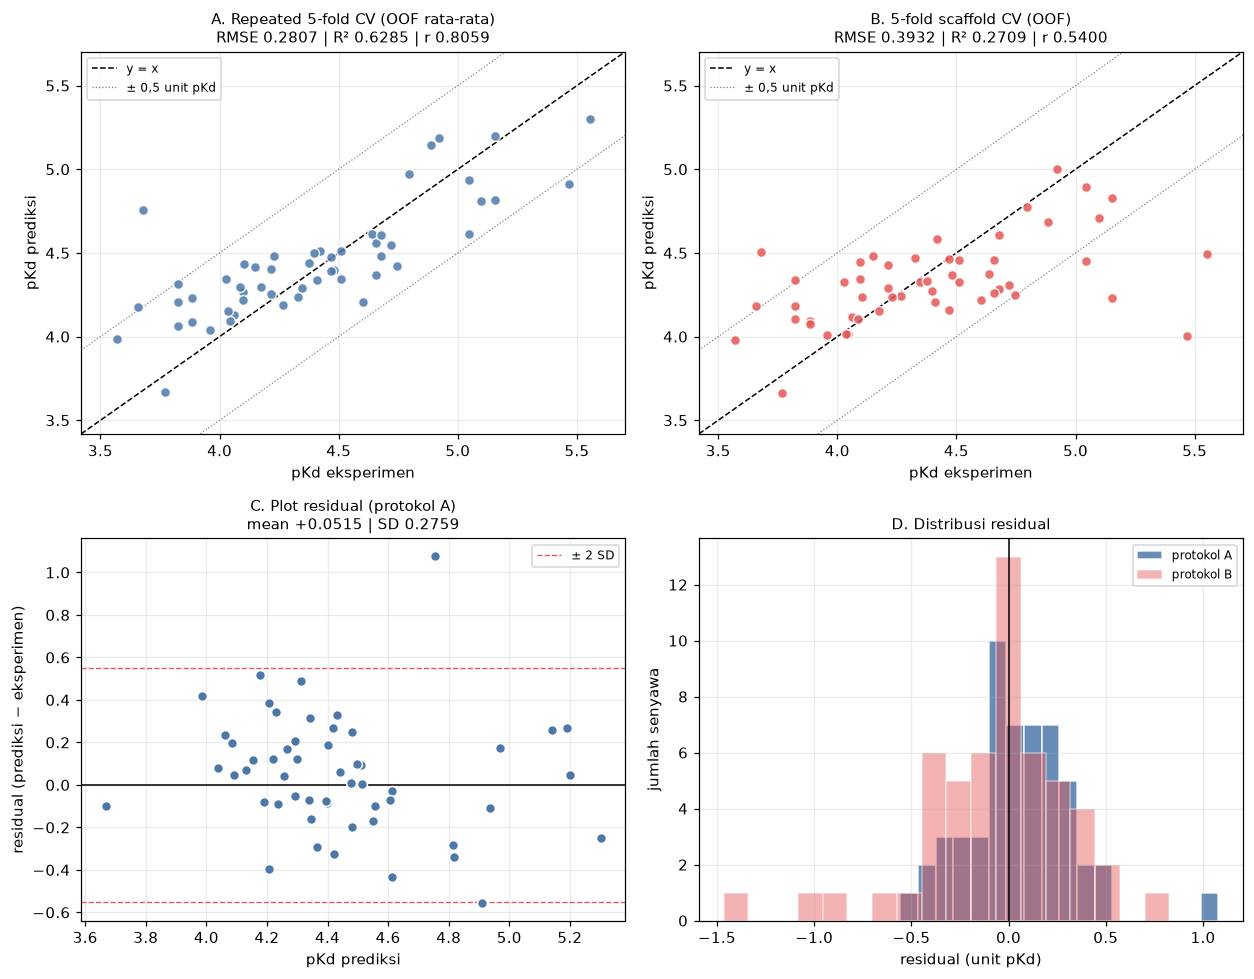

Grafik disimpan: USP5_ML_diagnostik.png (300 dpi)


In [43]:
fig, ax = plt.subplots(2, 2, figsize=(11.5, 9))

def av_plot(a, yt, yp, title, color):
    lo, hi = min(yt.min(), yp.min()) - .15, max(yt.max(), yp.max()) + .15
    a.plot([lo, hi], [lo, hi], "k--", lw=1, label="y = x")
    a.plot([lo, hi], [lo + .5, hi + .5], c="gray", ls=":", lw=.8)
    a.plot([lo, hi], [lo - .5, hi - .5], c="gray", ls=":", lw=.8, label="± 0,5 unit pKd")
    a.scatter(yt, yp, s=42, c=color, edgecolor="white", alpha=.85, zorder=3)
    a.set_xlim(lo, hi); a.set_ylim(lo, hi)
    a.set_xlabel("pKd eksperimen"); a.set_ylabel("pKd prediksi")
    a.set_title(f"{title}\nRMSE {np.sqrt(mean_squared_error(yt,yp)):.4f} | "
                f"R² {r2_score(yt,yp):.4f} | r {pearsonr(yt,yp)[0]:.4f}", fontsize=10)
    a.legend(fontsize=8, loc="upper left")

av_plot(ax[0,0], y, oof_A, "A. Repeated 5-fold CV (OOF rata-rata)", "#4C78A8")
av_plot(ax[0,1], y, oof_B, "B. 5-fold scaffold CV (OOF)",          "#E45756")

res_A_ = oof_A - y
ax[1,0].scatter(oof_A, res_A_, s=42, c="#4C78A8", edgecolor="white", zorder=3)
ax[1,0].axhline(0, c="k", lw=1)
ax[1,0].axhline( res_A_.std()*2, c="#E45756", ls="--", lw=.9, label="± 2 SD")
ax[1,0].axhline(-res_A_.std()*2, c="#E45756", ls="--", lw=.9)
ax[1,0].set_xlabel("pKd prediksi"); ax[1,0].set_ylabel("residual (prediksi − eksperimen)")
ax[1,0].set_title(f"C. Plot residual (protokol A)\nmean {res_A_.mean():+.4f} | SD {res_A_.std():.4f}",
                  fontsize=10)
ax[1,0].legend(fontsize=8)

ax[1,1].hist(res_A_, bins=18, color="#4C78A8", edgecolor="white", alpha=.85, label="protokol A")
ax[1,1].hist(oof_B - y, bins=18, color="#E45756", edgecolor="white", alpha=.45, label="protokol B")
ax[1,1].axvline(0, c="k", lw=1)
ax[1,1].set_xlabel("residual (unit pKd)"); ax[1,1].set_ylabel("jumlah senyawa")
ax[1,1].set_title("D. Distribusi residual", fontsize=10); ax[1,1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("USP5_ML_diagnostik.png", bbox_inches="tight")
plt.show()
print("Grafik disimpan: USP5_ML_diagnostik.png (300 dpi)")

In [45]:
# Analisis khusus kelompok pKd > 5 — titik lemah GNN sebelumnya (MAE 0,7457)
hi = y > 5
for nm, p, lab in [("Protokol A", oof_A, "random CV"), ("Protokol B", oof_B, "scaffold CV")]:
    print(f"{nm} ({lab}):")
    print(f"  seluruh 80 senyawa   MAE {mean_absolute_error(y, p):.4f}")
    print(f"  {hi.sum()} senyawa pKd > 5    MAE {mean_absolute_error(y[hi], p[hi]):.4f}  "
          f"(bias rata-rata {np.mean(p[hi]-y[hi]):+.4f})")
    print(f"  {(~hi).sum()} senyawa pKd ≤ 5   MAE {mean_absolute_error(y[~hi], p[~hi]):.4f}\n")

print(f"Model ini, protokol B, {hi.sum()} senyawa pKd > 5    : "
      f"MAE {mean_absolute_error(y[hi], oof_B[hi]):.4f} ({und}/{hi.sum()} underprediction)")

Protokol A (random CV):
  seluruh 80 senyawa   MAE 0.2127
  7 senyawa pKd > 5    MAE 0.2882  (bias rata-rata -0.2754)
  46 senyawa pKd ≤ 5   MAE 0.2012

Protokol B (scaffold CV):
  seluruh 80 senyawa   MAE 0.2732
  7 senyawa pKd > 5    MAE 0.7015  (bias rata-rata -0.7015)
  46 senyawa pKd ≤ 5   MAE 0.2080

Model ini, protokol B, 7 senyawa pKd > 5    : MAE 0.7015 (7/7 underprediction)


Tanimoto maksimum (leave-one-out): median 0.7885 | min 0.3673 | max 0.9149
Senyawa dengan kemiripan < 0,40 (di luar AD ketat): 1/53

Spearman (kemiripan vs |error|), protokol A: ρ = -0.1590  p = 0.2554
Spearman (kemiripan vs |error|), protokol B: ρ = +0.0490  p = 0.7276
(ρ negatif = makin mirip training, makin kecil error -> AD berperilaku sebagaimana mestinya)


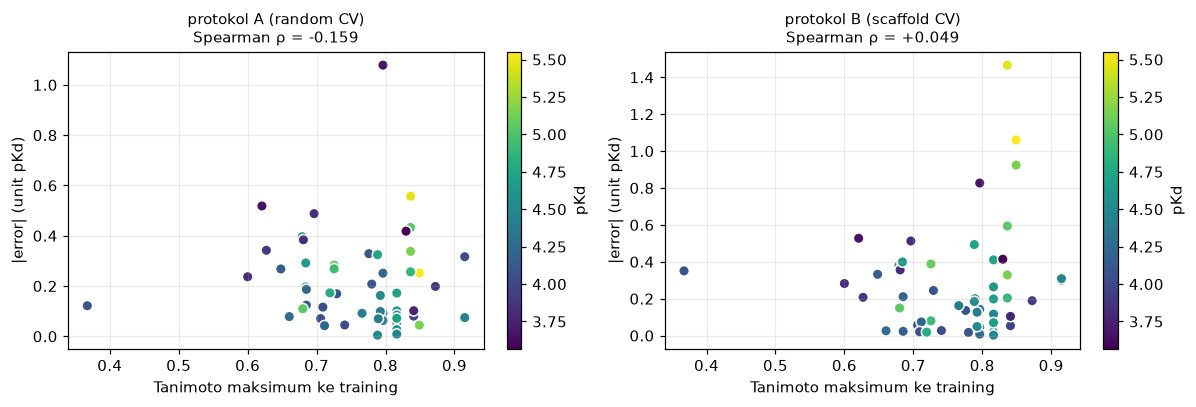

,n,MAE_A,MAE_B
kuartil_kemiripan,,,
Q1,13,0.2503,0.2798
Q2,12,0.1903,0.1449
Q3,9,0.2383,0.2306
Q4,19,0.1889,0.3698


In [46]:
# Tanimoto similarity maksimum tiap senyawa terhadap senyawa lain (leave-one-out)
bitgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
bitfps = [bitgen.GetFingerprint(m) for m in mols]

max_sim = np.zeros(len(y))
for i in range(len(y)):
    others = [bitfps[j] for j in range(len(y)) if j != i]
    max_sim[i] = max(DataStructs.BulkTanimotoSimilarity(bitfps[i], others))

abs_err_A = np.abs(oof_A - y)
abs_err_B = np.abs(oof_B - y)
rho_A = spearmanr(max_sim, abs_err_A)
rho_B = spearmanr(max_sim, abs_err_B)

print(f"Tanimoto maksimum (leave-one-out): median {np.median(max_sim):.4f} | "
      f"min {max_sim.min():.4f} | max {max_sim.max():.4f}")
print(f"Senyawa dengan kemiripan < 0,40 (di luar AD ketat): {(max_sim<0.40).sum()}/{len(y)}\n")
print(f"Spearman (kemiripan vs |error|), protokol A: ρ = {rho_A[0]:+.4f}  p = {rho_A[1]:.4f}")
print(f"Spearman (kemiripan vs |error|), protokol B: ρ = {rho_B[0]:+.4f}  p = {rho_B[1]:.4f}")
print("(ρ negatif = makin mirip training, makin kecil error -> AD berperilaku sebagaimana mestinya)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, err, lab, rho in [(ax[0], abs_err_A, "protokol A (random CV)", rho_A),
                         (ax[1], abs_err_B, "protokol B (scaffold CV)", rho_B)]:
    sct = a.scatter(max_sim, err, c=y, cmap="viridis", s=48, edgecolor="white")
    a.set_xlabel("Tanimoto maksimum ke training"); a.set_ylabel("|error| (unit pKd)")
    a.set_title(f"{lab}\nSpearman ρ = {rho[0]:+.3f}", fontsize=10)
    plt.colorbar(sct, ax=a, label="pKd", fraction=.046)
plt.tight_layout(); plt.show()

# Error terstratifikasi berdasarkan kuartil kemiripan
q = np.digitize(max_sim, np.quantile(max_sim, [.25, .5, .75]))
ad = pd.DataFrame({"kuartil_kemiripan": [f"Q{i+1}" for i in q], "err_A": abs_err_A, "err_B": abs_err_B})
display(ad.groupby("kuartil_kemiripan").agg(n=("err_A","size"), MAE_A=("err_A","mean"),
                                            MAE_B=("err_B","mean")).round(4))

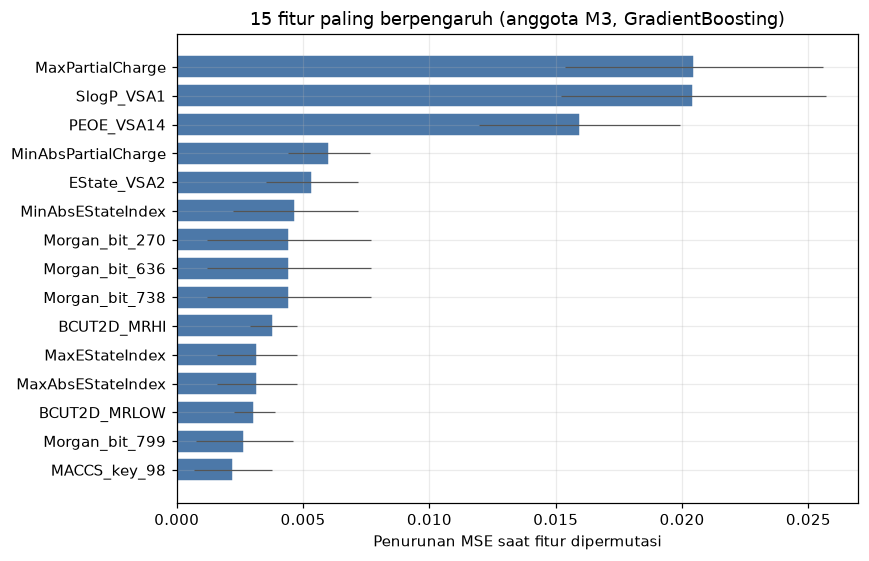

,fitur,importance,sd
0,MaxPartialCharge,0.02046,0.00509
1,SlogP_VSA1,0.02044,0.00523
2,PEOE_VSA14,0.01596,0.00397
3,MinAbsPartialCharge,0.00603,0.00163
4,EState_VSA2,0.00536,0.00182
5,MinAbsEStateIndex,0.00470,0.00247
6,Morgan_bit_270,0.00443,0.00324
7,Morgan_bit_636,0.00443,0.00324
8,Morgan_bit_738,0.00443,0.00324
9,BCUT2D_MRHI,0.00383,0.00094


Grafik disimpan: USP5_ML_importance.png (300 dpi)


In [47]:
tr_idx, te_idx = next(iter(StratifiedShuffleSplit(n_splits=1, test_size=20,
                                                  random_state=SEED).split(X, bins)))
m3 = make_member(2).fit(X[tr_idx], y[tr_idx])

pi = permutation_importance(m3, X[te_idx], y[te_idx], n_repeats=30,
                            random_state=SEED, scoring="neg_mean_squared_error")

feat_names = (list(desc_names)
              + [f"Morgan_bit_{i}" for i in range(MORGAN.shape[1])]
              + [f"MACCS_key_{i}"  for i in range(MACCS.shape[1])])

imp = pd.DataFrame({"fitur": feat_names,
                    "importance": pi.importances_mean,
                    "sd": pi.importances_std}).sort_values("importance", ascending=False)
top = imp.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.fitur, top.importance, xerr=top.sd, color="#4C78A8", edgecolor="white",
        error_kw=dict(lw=.8, ecolor="#555"))
ax.set_xlabel("Penurunan MSE saat fitur dipermutasi")
ax.set_title("15 fitur paling berpengaruh (anggota M3, GradientBoosting)")
plt.tight_layout(); plt.savefig("USP5_ML_importance.png", bbox_inches="tight"); plt.show()

display(imp.head(15).round(5).reset_index(drop=True))
print("Grafik disimpan: USP5_ML_importance.png (300 dpi)")

In [48]:
final_model = make_model().fit(X, y)

y_fit = final_model.predict(X)
print("Error pada data pelatihan (HANYA untuk sanity check, BUKAN performa):")
print(f"  RMSE_train {np.sqrt(mean_squared_error(y, y_fit)):.4f} | R²_train {r2_score(y, y_fit):.4f}")
print(f"\nPerforma yang sah dilaporkan:")
print(f"  Protokol A (repeated 5-fold CV) : RMSE {summ_A['RMSE']:.4f} ± {summ_A['RMSE_sd']:.4f} | "
      f"R² {summ_A['R2']:.4f} ± {summ_A['R2_sd']:.4f}")
print(f"  Protokol B (scaffold CV)        : RMSE {summ_B['RMSE']:.4f} | R² {summ_B['R2']:.4f}")
print(f"  Protokol C (hold-out 64/16 x20) : RMSE {summ_C['RMSE']:.4f} ± {summ_C['RMSE_sd']:.4f} | "
      f"R² {summ_C['R2']:.4f} ± {summ_C['R2_sd']:.4f}")

bundle = dict(model=final_model,
              feature_spec=dict(desc_names=list(desc_names), morgan_radius=2, morgan_bits=1024,
                                maccs=True, order=["DESC", "MORGAN", "MACCS"]),
              idx=dict(DESC=IDX_DESC, MORGAN=IDX_MORGAN, MACCS=IDX_MACCS,
                       FPMA=IDX_FPMA, DESCFP=IDX_DESCFP),
              member_names=MEMBER_NAMES,
              performance=dict(protokol_A=summ_A, protokol_B=summ_B, protokol_C=summ_C),
              n_train=len(y), seed=SEED)
joblib.dump(bundle, "USP5_pKd_ensemble_model.joblib")
print("\nModel disimpan: USP5_pKd_ensemble_model.joblib")
print("Catatan: saat memuat kembali dengan joblib.load, kelas AverageBlend dan BlockSelector")
print("harus sudah terdefinisi di namespace (jalankan sel Bagian 5 dan 6 lebih dulu).")

Error pada data pelatihan (HANYA untuk sanity check, BUKAN performa):
  RMSE_train 0.0517 | R²_train 0.9874

Performa yang sah dilaporkan:
  Protokol A (repeated 5-fold CV) : RMSE 0.3325 ± 0.0598 | R² 0.4653 ± 0.1870
  Protokol B (scaffold CV)        : RMSE 0.3932 | R² 0.2709
  Protokol C (hold-out 64/16 x20) : RMSE 0.3084 ± 0.1030 | R² 0.5054 ± 0.2659

Model disimpan: USP5_pKd_ensemble_model.joblib
Catatan: saat memuat kembali dengan joblib.load, kelas AverageBlend dan BlockSelector
harus sudah terdefinisi di namespace (jalankan sel Bagian 5 dan 6 lebih dulu).


In [49]:
def featurize_smiles(smiles_list):
    """Ubah daftar SMILES menjadi matriks fitur dengan urutan blok identik dengan training."""
    ms = [Chem.MolFromSmiles(s) for s in smiles_list]
    if any(m is None for m in ms):
        bad = [s for s, m in zip(smiles_list, ms) if m is None]
        raise ValueError(f"SMILES tidak valid: {bad}")
    d  = np.nan_to_num(np.array([calc.CalcDescriptors(m) for m in ms], dtype=float),
                       nan=0.0, posinf=0.0, neginf=0.0)
    mo = np.array([mgen.GetCountFingerprintAsNumPy(m) for m in ms], dtype=float)
    ma = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in ms], dtype=float)
    return np.hstack([d, mo, ma]), ms

def predict_pKd(smiles_list, model=None, with_ad=True):
    """
    Prediksi pKd untuk SMILES baru, lengkap dengan indikator applicability domain.

    Mengembalikan DataFrame: smiles, pKd_prediksi, Kd_nM_prediksi, prediksi tiap anggota,
    simpangan antar-anggota (proksi ketidakpastian), Tanimoto maksimum ke training, dan
    status AD.
    """
    model = model or final_model
    Xn, ms = featurize_smiles(smiles_list)
    pred = model.predict(Xn)
    mem  = model.predict_members(Xn)

    out = pd.DataFrame({"smiles": smiles_list,
                        "pKd_prediksi": pred,
                        "Kd_nM_prediksi": 10 ** (9 - pred)})
    for nm, row in zip(MEMBER_NAMES, mem):
        out[nm.split("_")[0] + "_pred"] = row
    out["sd_antar_anggota"] = mem.std(axis=0)

    if with_ad:
        fps = [bitgen.GetFingerprint(m) for m in ms]
        sims = [max(DataStructs.BulkTanimotoSimilarity(f, bitfps)) for f in fps]
        out["tanimoto_max_training"] = sims
        out["status_AD"] = ["dalam AD" if s >= 0.40 else "DI LUAR AD - hati-hati" for s in sims]
    return out

# Demonstrasi: 3 senyawa dari dataset (kontrol) + 2 struktur uji
demo = list(df.canonical_smiles[:3]) + [
    "O=C(O)CCc1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1",   # mengikuti scaffold dominan
    "CCOC(=O)c1ccc(N2CCN(c3ncccn3)CC2)cc1",             # kerangka asing
]
hasil = predict_pKd(demo)
pd.set_option("display.width", 200)
display(hasil.round(4))

print("\npKd eksperimen 3 senyawa kontrol pertama:", np.round(y[:3], 4))


,smiles,pKd_prediksi,Kd_nM_prediksi,M1_pred,M2_pred,M3_pred,sd_antar_anggota,tanimoto_max_training,status_AD
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.8945,127511.3161,3.8880,3.8984,3.8969,0.0046,1.0000,dalam AD
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.3331,46441.7269,4.3085,4.3454,4.3454,0.0174,1.0000,dalam AD
2,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.6484,22467.4946,4.6787,4.6324,4.6343,0.0214,1.0000,dalam AD
3,O=C(O)CCc1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1,4.8380,14522.7825,4.8423,4.8318,4.8398,0.0044,0.7234,dalam AD
4,CCOC(=O)c1ccc(N2CCN(c3ncccn3)CC2)cc1,4.3901,40728.4451,4.4227,4.3766,4.3710,0.0232,0.3000,DI LUAR AD - hati-hati



pKd eksperimen 3 senyawa kontrol pertama: [3.8861 4.3468 4.6383]


In [50]:
comparison = pd.DataFrame([
    ("Ensemble descriptor-based (notebook ini)",
     "Repeated 5-fold CV (5 ulangan)", summ_A["RMSE"], summ_A["MAE"], summ_A["R2"]),
    ("Ensemble descriptor-based (notebook ini)",
     "5-fold scaffold CV (OOF)",       summ_B["RMSE"], summ_B["MAE"], summ_B["R2"]),
    ("Ensemble descriptor-based (notebook ini)",
     "Hold-out 80/20 (20 ulangan)",    summ_C["RMSE"], summ_C["MAE"], summ_C["R2"]),
    ("Baseline (rata-rata training)", "Repeated 5-fold CV",
     rb.RMSE.mean(), rb.MAE.mean(), rb.R2.mean()),
], columns=["Model", "Protokol evaluasi", "RMSE", "MAE", "R²"])

print("=== TABEL PERBANDINGAN ===\n")
display(comparison.round(4))
comparison.round(4).to_csv("USP5_tabel_perbandingan.csv", index=False)

# Tabel prediksi per senyawa untuk lampiran
per_cmp = pd.DataFrame({
    "chembl_id": df.chembl_id, "smiles": df.canonical_smiles,
    "scaffold": df.scaffold, "pKd_eksperimen": y,
    "pKd_pred_A_randomCV": oof_A, "residual_A": oof_A - y,
    "pKd_pred_B_scaffoldCV": oof_B, "residual_B": oof_B - y,
    "tanimoto_max": max_sim,
}).sort_values("pKd_eksperimen")
per_cmp.round(4).to_csv("USP5_prediksi_per_senyawa.csv", index=False)

print("\nBerkas keluaran:")
for f in ["USP5_tabel_perbandingan.csv", "USP5_prediksi_per_senyawa.csv",
          "USP5_ML_diagnostik.png", "USP5_ML_importance.png",
          "USP5_pKd_ensemble_model.joblib"]:
    if os.path.exists(f):
        print(f"  {f}  ({os.path.getsize(f)/1024:.1f} KB)")
display(per_cmp.head(8).round(4))

=== TABEL PERBANDINGAN ===



,Model,Protokol evaluasi,RMSE,MAE,R²
0,Ensemble descriptor-based (notebook ini),Repeated 5-fold CV (5 ulangan),0.3325,0.2281,0.4653
1,Ensemble descriptor-based (notebook ini),5-fold scaffold CV (OOF),0.3932,0.2732,0.2709
2,Ensemble descriptor-based (notebook ini),Hold-out 80/20 (20 ulangan),0.3084,0.2289,0.5054
3,Baseline (rata-rata training),Repeated 5-fold CV,0.4663,0.3789,-0.0251



Berkas keluaran:
  USP5_tabel_perbandingan.csv  (0.4 KB)
  USP5_prediksi_per_senyawa.csv  (7.6 KB)
  USP5_ML_diagnostik.png  (513.3 KB)
  USP5_ML_importance.png  (177.4 KB)
  USP5_pKd_ensemble_model.joblib  (2642.7 KB)


,chembl_id,smiles,scaffold,pKd_eksperimen,pKd_pred_A_randomCV,residual_A,pKd_pred_B_scaffoldCV,residual_B,tanimoto_max
41,CHEMBL5269641,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CC(c3ccccc3)C2)cc1,O=S(=O)(c1ccccc1)N1CC(c2ccccc2)C1,3.5686,3.9868,0.4182,3.9825,0.4139,0.8298
47,CHEMBL5274321,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC3(CC2)OCc2ccc...,O=S(=O)(c1ccccc1)N1CCC2(CC1)OCc1ccccc12,3.6576,4.1759,0.5183,4.1851,0.5276,0.6207
13,CHEMBL5286558,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1,3.6778,4.7562,1.0785,4.5048,0.8270,0.7963
43,CHEMBL5275351,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2Cc3ccccc3C2)cc1,O=S(=O)(c1ccccc1)N1Cc2ccccc2C1,3.7696,3.6679,-0.1016,3.6655,-0.1041,0.8409
37,CHEMBL5282333,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCN(c3ccccc3)CC2...,O=S(=O)(c1ccccc1)N1CCN(c2ccccc2)CC1,3.8239,4.2079,0.3840,4.1799,0.3560,0.6809
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,O=S(=O)(c1cc[nH]c1)N1CCC(c2ccccc2)CC1,3.8239,4.3117,0.4878,4.3366,0.5127,0.6964
21,CHEMBL5284407,CN1CCC(NS(=O)(=O)c2ccc(C(=O)NCC(=O)O)cc2)CC1,O=S(=O)(NC1CCNCC1)c1ccccc1,3.8239,4.0608,0.2369,4.1062,0.2823,0.6000
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,O=C1Cc2ccccc2N1C1CCN(S(=O)(=O)c2ccccc2)CC1,3.8861,4.2282,0.3421,4.0934,0.2074,0.6271
